In [28]:
import import_first

from common import (deploy_utils, feature_utils, plot_utils, cluster_utils)

from pathlib import PurePath

import time
import numpy as np
import matplotlib.pyplot as plt

## **1. Get data (two datasets)**

In [29]:
traces = {}

traces["morning"] = deploy_utils.Trace.read_trace(
    file_path=PurePath("..") / ".." / "data" / "6_to_8am.csv")
print("morning:\n" + deploy_utils.Trace.summarize_trace(trace=traces["morning"]))

morning:
[+] number of vehicles: 75516
[+] number of lines: 2182717
[+] x interval: [0, 99]
[+] y interval: [0, 99]


In [30]:
cell_dfs = {}

cell_dfs["morning"] = feature_utils.Features.create_basic_cell_df(trace=traces["morning"])

In [31]:
cell_dfs_no_outl = {}

cell_dfs_no_outl["morning"] = \
cluster_utils.Preprocessing.remove_outliers(
    df=cell_dfs["morning"],
    features=cell_dfs["morning"].columns.tolist()
)

## **2. Data Distribution (Morning)**

### 2.1 Features Histogram (total / no outliers)

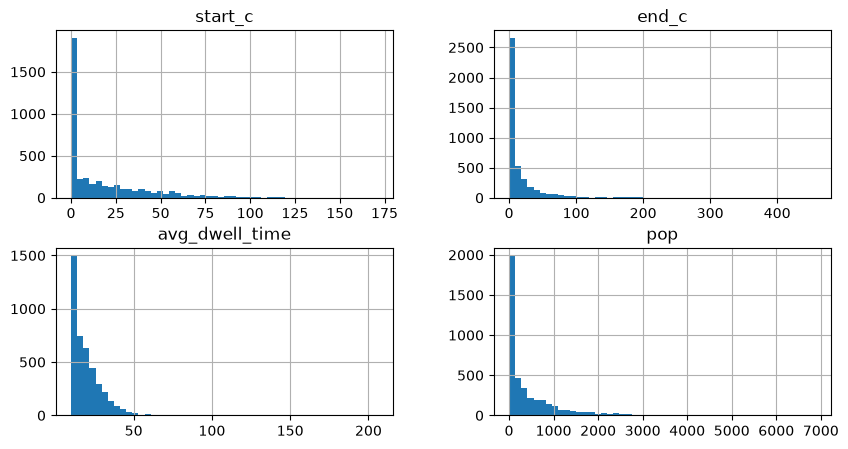

In [32]:
cell_dfs["morning"].hist(figsize=(10, 5), bins=50) ; plt.show()

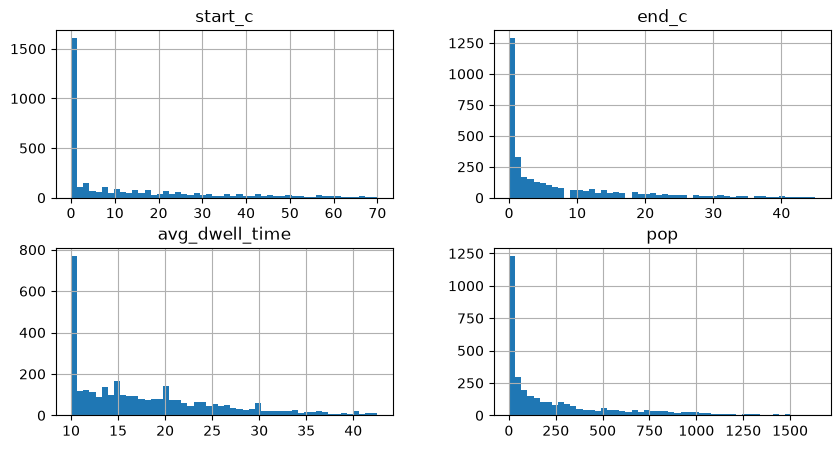

In [33]:
cell_dfs_no_outl["morning"].hist(figsize=(10, 5), bins=50) ; plt.show()

### 2.2 Correlation matrix (no outliers)

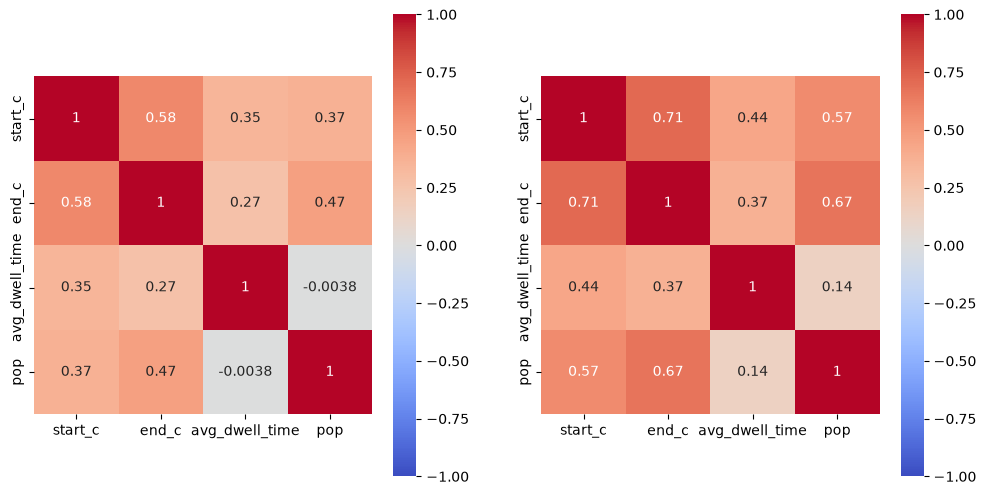

In [34]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))

plot_utils.Plot.plot_correlation_matrix(
    df=cell_dfs_no_outl["morning"],
    features=cell_dfs["morning"].columns.tolist(),
    method="pearson",
    ax=ax[0]
)

plot_utils.Plot.plot_correlation_matrix(
    df=cell_dfs_no_outl["morning"],
    features=cell_dfs["morning"].columns.tolist(),
    method="spearman",
    ax=ax[1]
)
plt.show()

### 2.3 2D Histograms (total / no outliers)

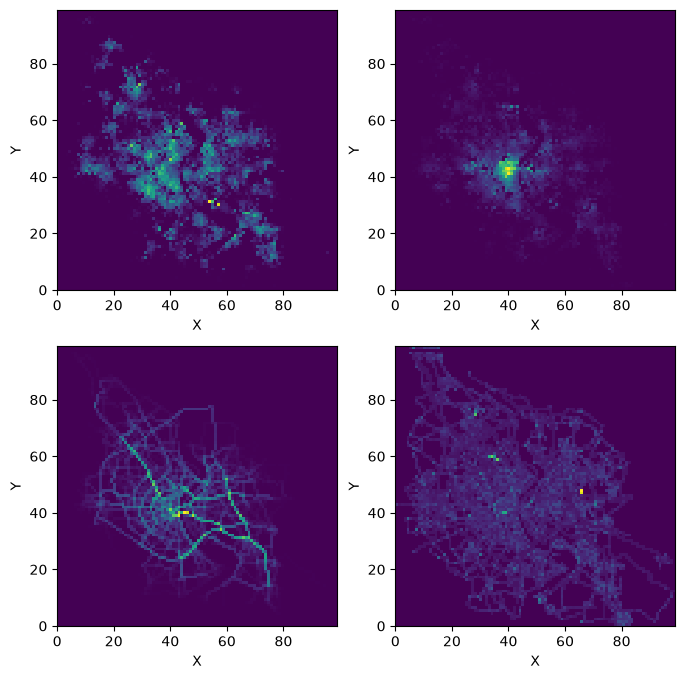

In [35]:
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(8, 8))

plot_utils.Plot.plot_cell_feature_2d_histogram(
    cell_df=cell_dfs["morning"], feature="start_c", ax=ax[0,0])

plot_utils.Plot.plot_cell_feature_2d_histogram(
    cell_df=cell_dfs["morning"], feature="end_c", ax=ax[0,1])

plot_utils.Plot.plot_cell_feature_2d_histogram(
    cell_df=cell_dfs["morning"], feature="pop", ax=ax[1,0])

plot_utils.Plot.plot_cell_feature_2d_histogram(
    cell_df=cell_dfs["morning"], feature="avg_dwell_time", ax=ax[1,1])

plt.show()

## **Pair plots**

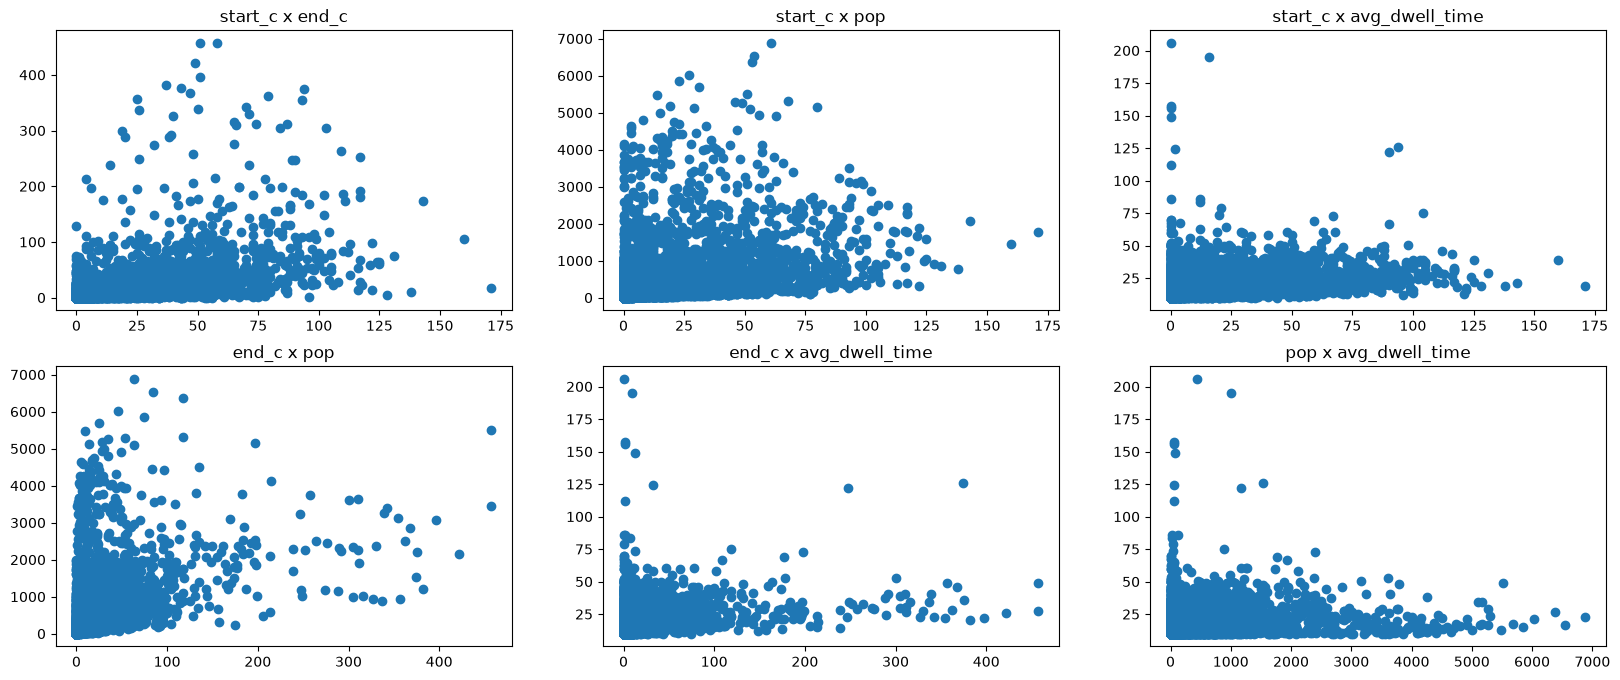

In [36]:
from itertools import combinations

fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(20, 8))
row, col = 0, 0
for comb in combinations(
    iterable=["start_c", "end_c", "pop", "avg_dwell_time"], r=2):

    ax[row, col].scatter(cell_dfs["morning"][comb[0]], cell_dfs["morning"][comb[1]])
    ax[row, col].set_title(f"{comb[0]} x {comb[1]}")

    col += 1

    if col == 3:
        col = 0
        row += 1

plt.show()